# Ajuste, todos los j, sensibilidad al intercepto y orden cubico

Seguimiento solicitado sobre la primera prueba. Se conservan las etiquetas
manuales, los 72 rollouts clasificables, las mismas particiones externas,
los mismos cinco pasos de entrenamiento (j=0,32,64,128,192), K=1 y las 36 capas.
Los 28 X no participan del ajuste, PCA ni seleccion de hiperparametros.
La adquisicion original y los resultados v1 se conservan.

## 1. Como se ajusto el decoder original

Se entreno una regresion logistica L2, no cuadrados minimos. Los cuadrados
minimos eran el procedimiento del trabajo anterior con una dificultad continua.
Aqui el objetivo observado es una etiqueta manual binaria por rollout.

Para cada capa, PCA se ajusto sobre los promedios acumulativos de los rollouts
de entrenamiento y sus cinco pasos j. Se retuvo una componente por capa. Sus
coordenadas se estandarizaron con media y desviacion del mismo entrenamiento.
Llamemos z al vector de estas 36 coordenadas estandarizadas y phi(z) a sus
monomios de grado uno y dos, sin repetir los productos simetricos.

$$s=b_z+w^\top\phi(z),\qquad p=\frac{1}{1+\exp(-s)}.$$

La implementacion original utilizo `LogisticRegression` de scikit-learn con
solver `liblinear`, `penalty='l2'`, maximo 3000 iteraciones, tolerancia por defecto
1e-4 y `intercept_scaling=100`. En su convencion de suma de perdidas, el objetivo es

$$\mathcal L=\sum_n[\log(1+\exp(s_n))-Y_n s_n]
+\frac{\lVert w\rVert_2^2}{2C}+\frac{b_z^2}{2C\,100^2}.$$

El intercepto tiene una penalizacion pequena, no exactamente cero. w contiene
coeficientes de monomios; la norma usada no es directamente la norma de
Frobenius de H. Para escribir 1/2 x^T H x, la diagonal de H lleva dos veces
el coeficiente del monomio cuadrado y los elementos cruzados llevan el
coeficiente del monomio correspondiente. Se guardo ademas la transformacion
de los coeficientes a las coordenadas PCA sin estandarizar.

Tres folds externos separaron rollouts completos. Dentro de cada entrenamiento
externo, otros tres folds eligieron C en {0.001,0.01,0.1,1}, minimizando log-loss
de validacion sobre los cinco pasos. PCA y escalado se reajustaron dentro de
cada entrenamiento interno. Todos los prefijos de un rollout quedaron juntos.
La etiqueta final se repite para los cinco estados, que no son cinco muestras
independientes. Los mismos parametros del decoder se utilizan para todo j.

## 2. Trayectorias token a token

Ahora se calcula una prediccion para **cada j entero de 0 a 192**, para los mismos
72 rollouts y con modelos externos que no los vieron durante el ajuste.
Para r0001 y r0026 se extiende la curva hasta el ultimo token valido,
incluido EOS en r0026. No se usa padding.

El encoder es lineal y fijo: podemos proyectar los tokens y acumular esas
proyecciones para obtener el mismo promedio proyectado. Las diferencias de
redondeo frente a la cache float32 v1 se registran por rollout.

El entrenamiento sigue usando los cinco pasos declarados; evaluar cada token
no significa reajustar cada token. Despues de j=192 las curvas de los dos casos
son extrapolaciones del horizonte temporal y se muestran en zona gris y con
linea discontinua. Las metricas poblacionales se limitan a 0..192 para no cambiar
la cohorte segun que respuestas ya terminaron.

## 3. Que significa la constante y que prueba hacemos

El intercepto es un score sin unidades de probabilidad. Su valor puede ser
negativo o mayor que uno. Ademas depende del origen de coordenadas: trasladar
las coordenadas cambia b y g sin cambiar las predicciones, si se transforman
coherentemente los coeficientes. En el modelo original, el estado inicial no
esta necesariamente en x=0, por lo que b no es por si solo el score inicial.

Para hacer interpretable la prueba, centramos las caracteristicas del
decoder en el prompt compartido, sin modificar las direcciones PCA:

$$F(z)=\phi(z)-\phi(z_0),\qquad s_j=\beta+w^\top F(z_j),\qquad s_0=\beta.$$

Se conservan las mismas penalizaciones de los coeficientes w. Aqui beta es
exactamente el logit inicial del prompt. Se prueban los cinco valores
0,0.25,0.5,0.75,1, que corresponden a probabilidades iniciales entre 0.5 y
0.731 aproximadamente; NO a probabilidades entre cero y uno.
Las probabilidades exactamente 0 y 1 requeririan logits infinitos.

Se distinguen dos experimentos:

- **Inicializacion:** beta empieza en cada valor y despues se optimiza junto
  con w. Se comparan iteraciones, objetivo, gradiente y predicciones finales.
- **Constante fija:** beta permanece en ese valor y solo se optimiza w.
  Esto cambia el problema de ajuste; la convergencia no puede eliminar una
  restriccion fija.

Se usa L-BFGS-B con gradiente analitico, maxiter=2000, gtol=1e-8 y ftol=1e-13:

$$\mathcal L=\frac1n\sum_n[\log(1+\exp(s_n))-Y_n s_n]
+\frac{\lVert w\rVert_2^2}{2Cn}.$$

En esta prueba beta no se penaliza. C se mantiene en el valor elegido en los
folds internos del cuadratico original, sin consultar el test. Cada beta se
ajusta con los mismos datos y el mismo C dentro de cada fold. Para encoder fijo,
la regresion es convexa en sus coeficientes; cambiar la inicializacion no deberia
producir soluciones distintas al converger. Se verifica numericamente.

El baseline constante original predice la prevalencia de entrenamiento:
51/72=0.7083 globalmente. Su logit es log(51/21), aproximadamente 0.8873.
Esto describe este prompt y este criterio manual, no una tendencia universal
de la LLM. No tenemos respuestas de un prompt como "banana split" en esta
adquisicion: esta prueba no establece generalizacion entre prompts. Modificar
el intercepto no reemplaza medirlos e incorporarlos al entrenamiento y evaluacion.

## 4. Un orden mas: termino cubico

Se interpreta la propuesta como extender la expansion hasta grado tres:

$$s_j^{(b)}=b_0+\sum_a g_a x_{aj}^{(b)}
+\frac12\sum_{a,c}H_{ac}x_{aj}^{(b)}x_{cj}^{(b)}
+\frac1{3!}\sum_{a,c,d}U_{acd}x_{aj}^{(b)}x_{cj}^{(b)}x_{dj}^{(b)}.$$

Los indices a,c,d agrupan direccion PCA y capa; b identifica el rollout.
El tensor U es simetrico y permite dependencias de tercer orden. Con d=36
coordenadas, se agregan 8436 monomios y se pasa de 703 a **9139 parametros**,
frente a solo 72 rollouts. La regularizacion se elige con el mismo esquema
anidado y la misma grilla, sin elegir el grado con el test. Es una comparacion
exploratoria posterior al resultado cuadratico, no una confirmacion independiente.

Se guardan coeficientes y tensor U en coordenadas estandarizadas. Que un modelo
de mayor orden mejore el ajuste de entrenamiento no basta para justificarlo:
la comparacion relevante es la log-loss y discriminacion fuera de entrenamiento.

In [1]:
from pathlib import Path
import sys
import json
RAIZ=next((p for p in (Path.cwd(),*Path.cwd().parents)
           if (p/'scripts/glossary_decoder_extensions.py').exists()),None)
if RAIZ is None:
    raise FileNotFoundError('Abra el notebook en el workspace o indique RAIZ.')
sys.path.insert(0,str(RAIZ/'scripts'))
from glossary_decoder_extensions import run, figures
SALIDA=RAIZ/'analysis/glossary/decoder_v2_checks'
resultado=run(RAIZ,SALIDA)
print(json.dumps(resultado['summary'],indent=2))

Extension fold 1/3
  Cubic C=0.01; intercept diagnostics
  Dense curves 8/24
  Dense curves 16/24
  Dense curves 24/24
Extension fold 2/3
  Cubic C=0.001; intercept diagnostics
  Dense curves 8/24
  Dense curves 16/24
  Dense curves 24/24
Extension fold 3/3
  Cubic C=0.001; intercept diagnostics
  Dense curves 8/24
  Dense curves 16/24
  Dense curves 24/24
{
  "primary_j192": [
    {
      "model": "constant",
      "j": 192,
      "AUROC": 0.5,
      "Brier": 0.2065972222222222,
      "log_loss": 0.6036372515003262,
      "balanced_accuracy": 0.5
    },
    {
      "model": "linear",
      "j": 192,
      "AUROC": 0.6293183940242764,
      "Brier": 0.19955846952769785,
      "log_loss": 0.5784812159093088,
      "balanced_accuracy": 0.49019607843137253
    },
    {
      "model": "diagonal",
      "j": 192,
      "AUROC": 0.6900093370681606,
      "Brier": 0.1909695553999114,
      "log_loss": 0.552744659172062,
      "balanced_accuracy": 0.5322128851540616
    },
    {
      "model":

In [2]:
rutas_figuras=figures(resultado,SALIDA)
print('\n'.join(str(p) for p in rutas_figuras))

c:\Users\User\Documents\Codex\2026-06-19\en-c-users-user-desktop-dstat\output\analisis_glosario_100\decoder_v2_checks\01_dense_reference_cases.png
c:\Users\User\Documents\Codex\2026-06-19\en-c-users-user-desktop-dstat\output\analisis_glosario_100\decoder_v2_checks\02_dense_metrics_and_cubic.png
c:\Users\User\Documents\Codex\2026-06-19\en-c-users-user-desktop-dstat\output\analisis_glosario_100\decoder_v2_checks\03_intercept_initialization_convergence.png
c:\Users\User\Documents\Codex\2026-06-19\en-c-users-user-desktop-dstat\output\analisis_glosario_100\decoder_v2_checks\04_fixed_vs_learned_intercept.png
c:\Users\User\Documents\Codex\2026-06-19\en-c-users-user-desktop-dstat\output\analisis_glosario_100\decoder_v2_checks\05_fixed_intercept_case_trajectories.png


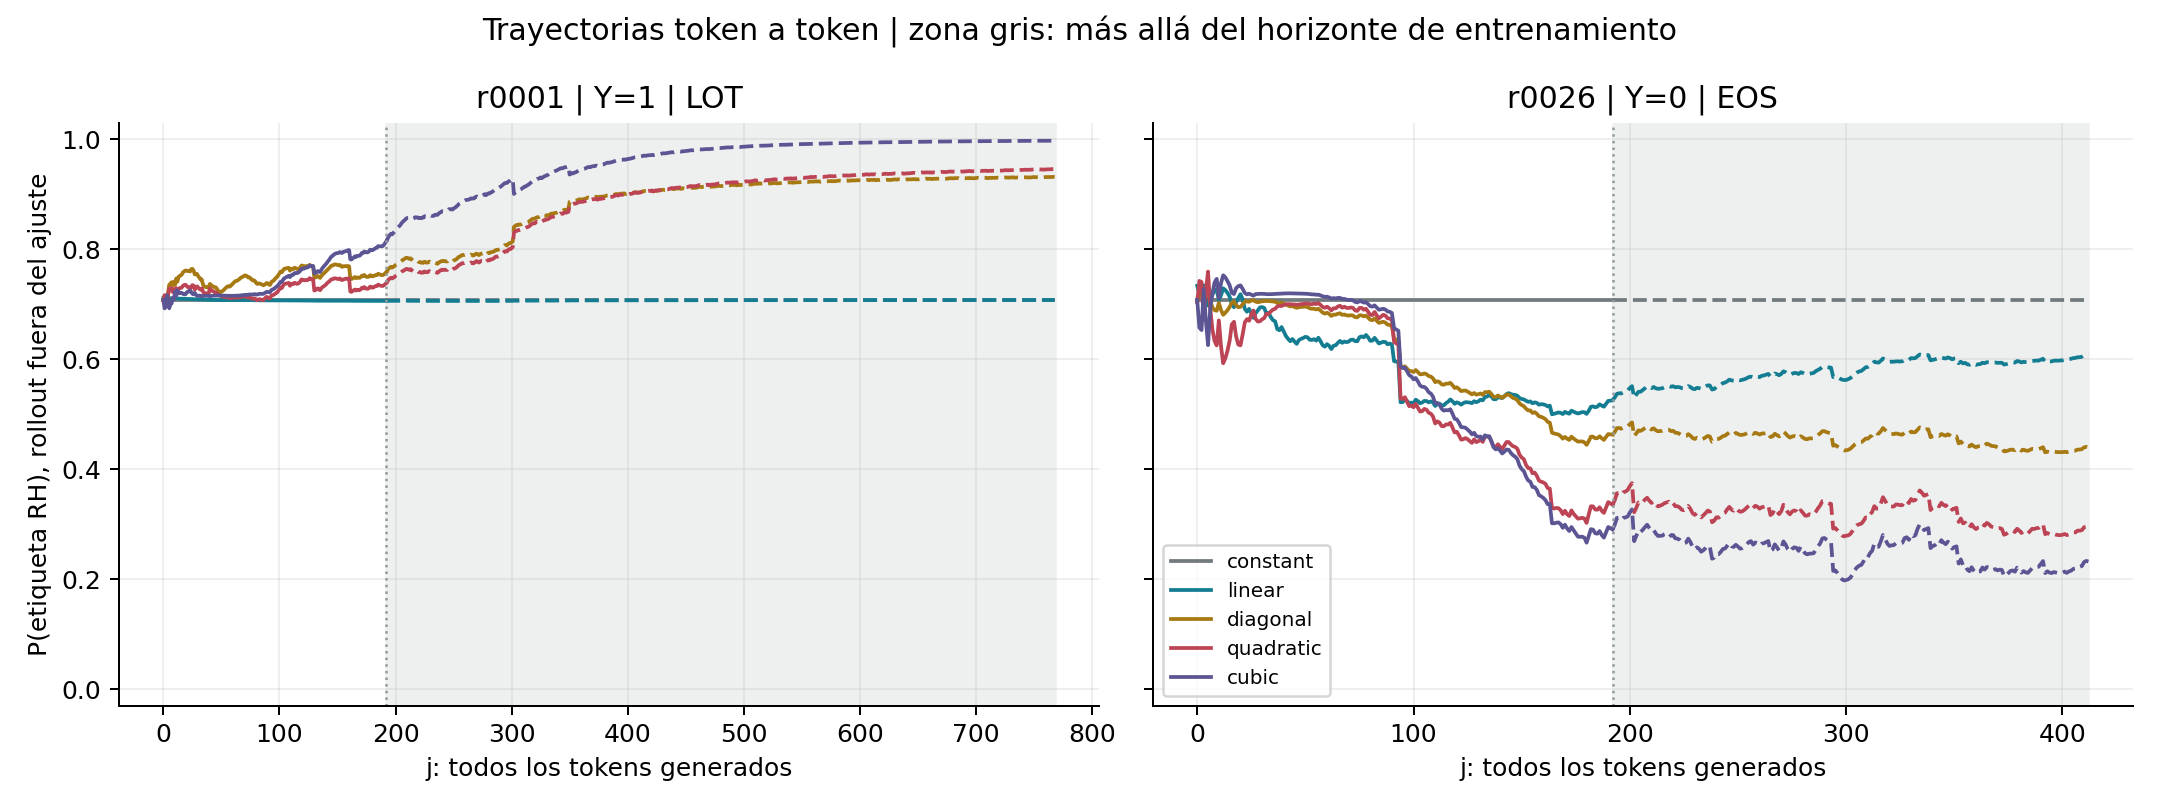

In [3]:
from IPython.display import Image, display
display(Image(filename=str(SALIDA/'01_dense_reference_cases.png')))

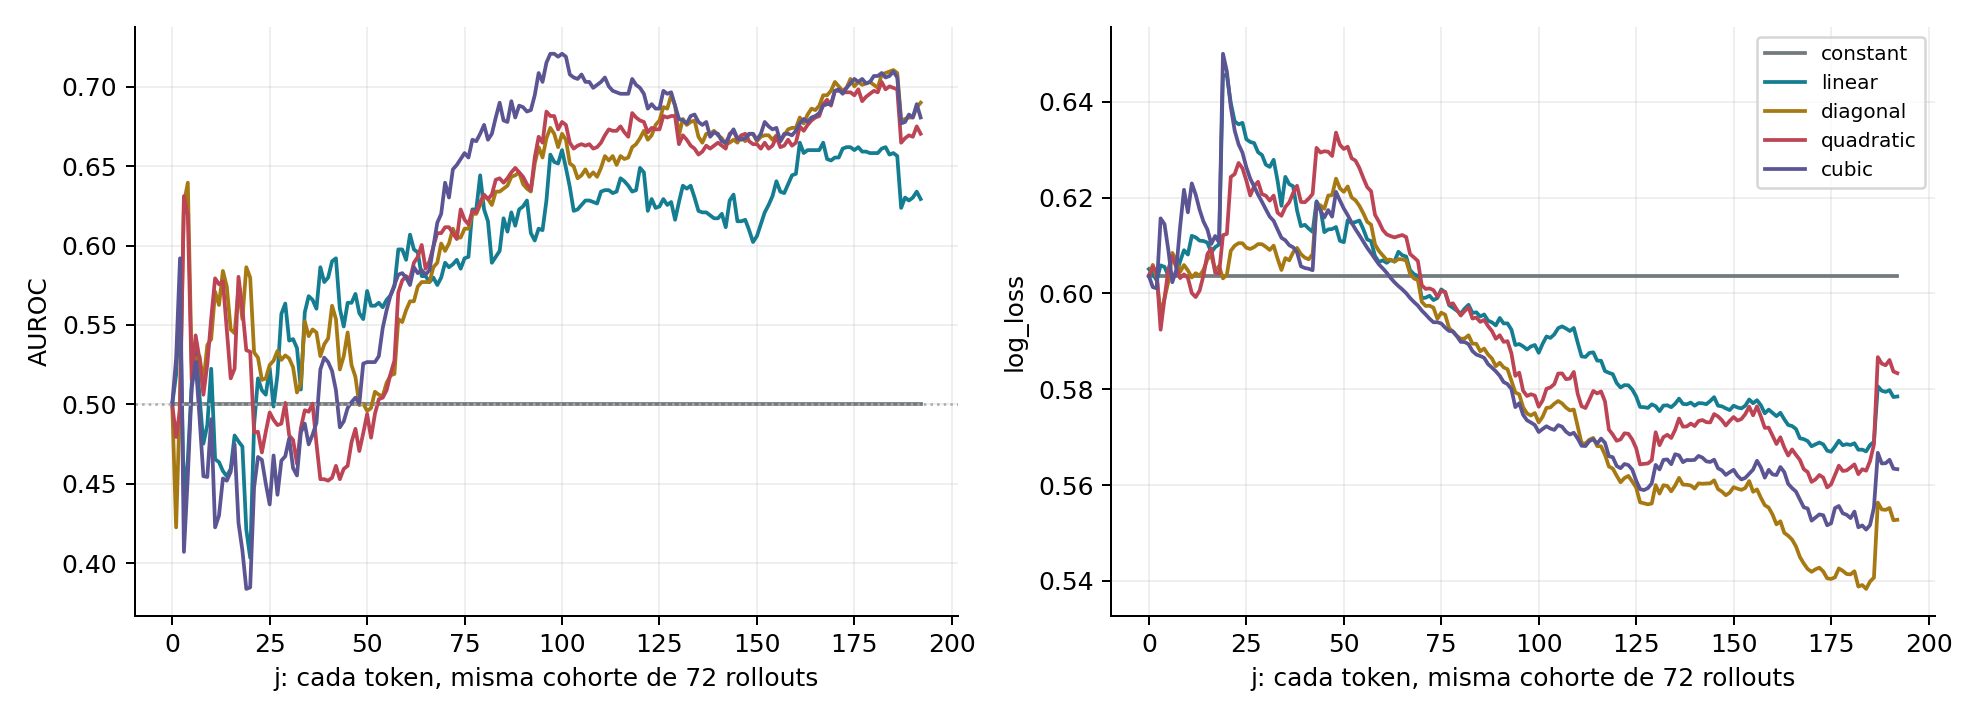

In [4]:
from IPython.display import Image, display
display(Image(filename=str(SALIDA/'02_dense_metrics_and_cubic.png')))

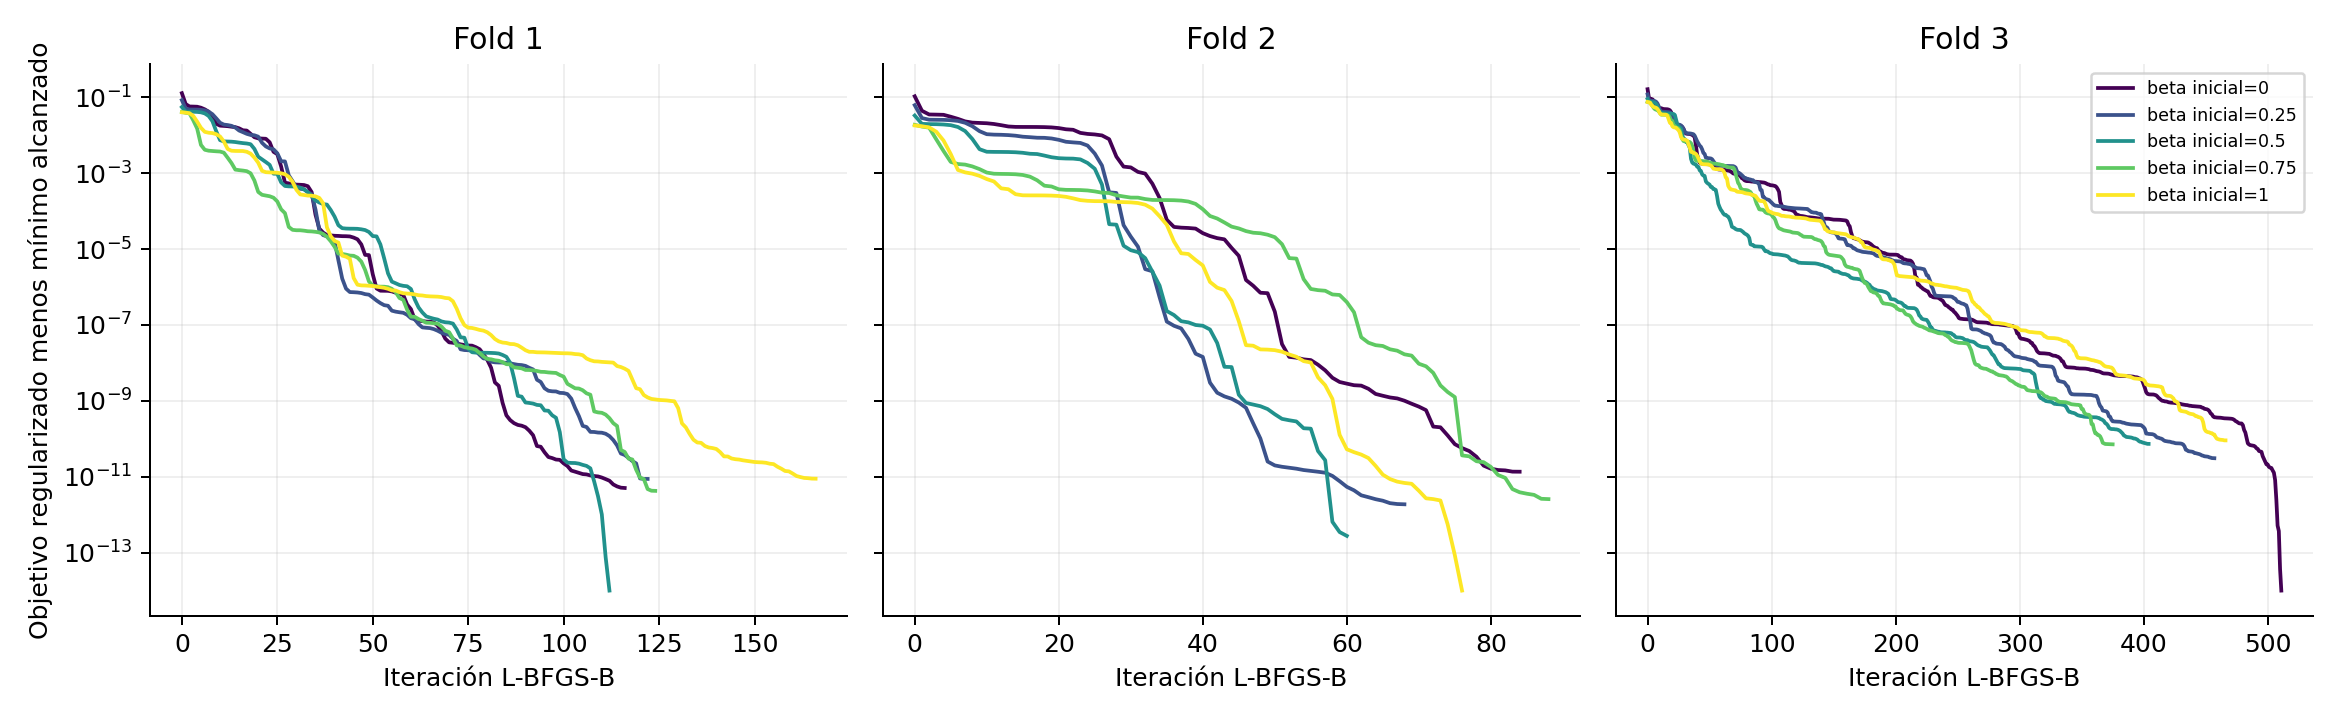

In [5]:
from IPython.display import Image, display
display(Image(filename=str(SALIDA/'03_intercept_initialization_convergence.png')))

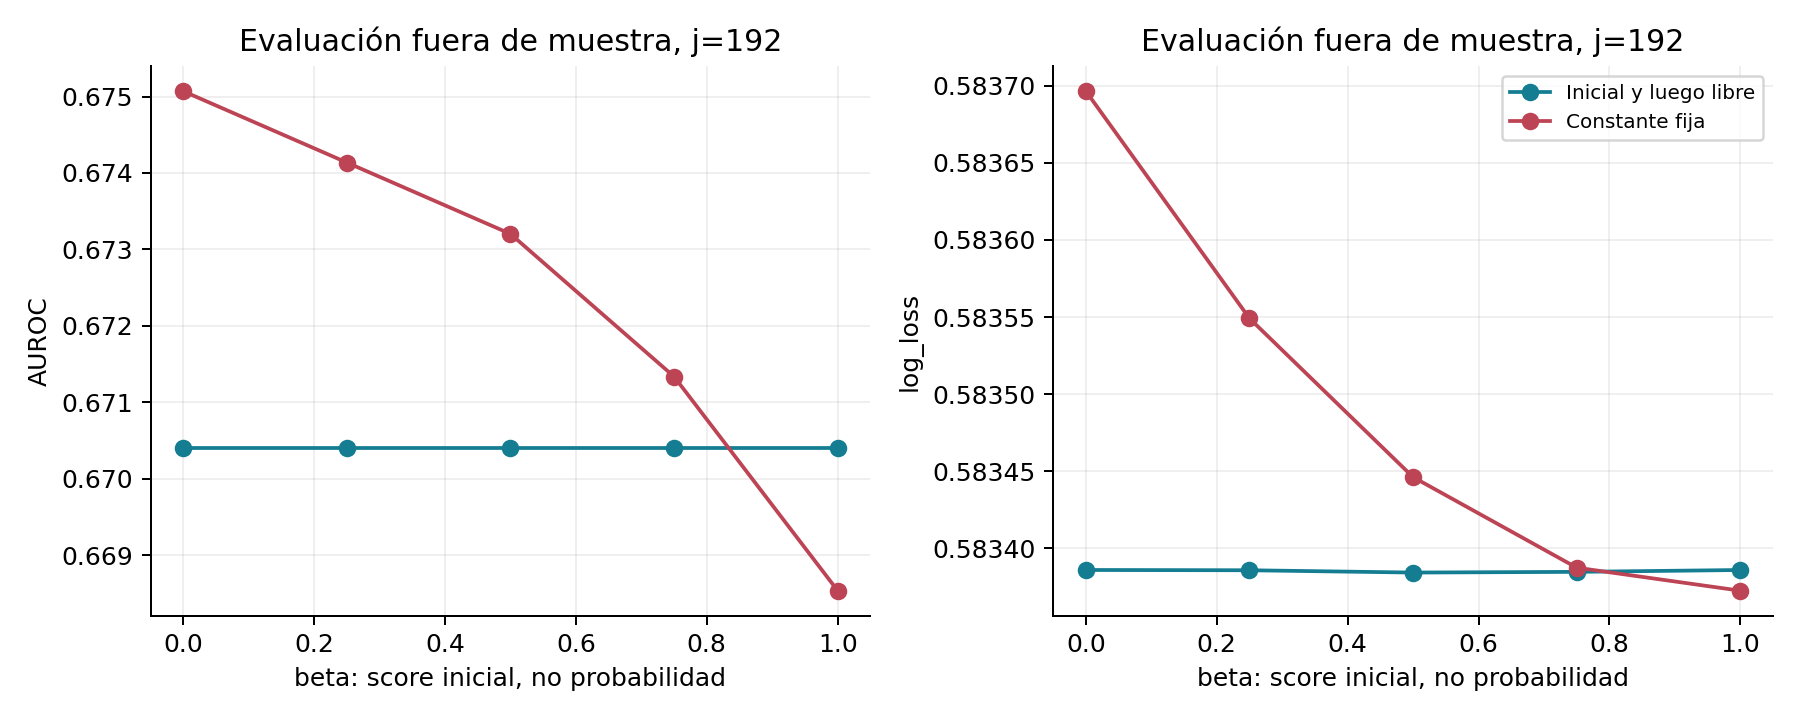

In [6]:
from IPython.display import Image, display
display(Image(filename=str(SALIDA/'04_fixed_vs_learned_intercept.png')))

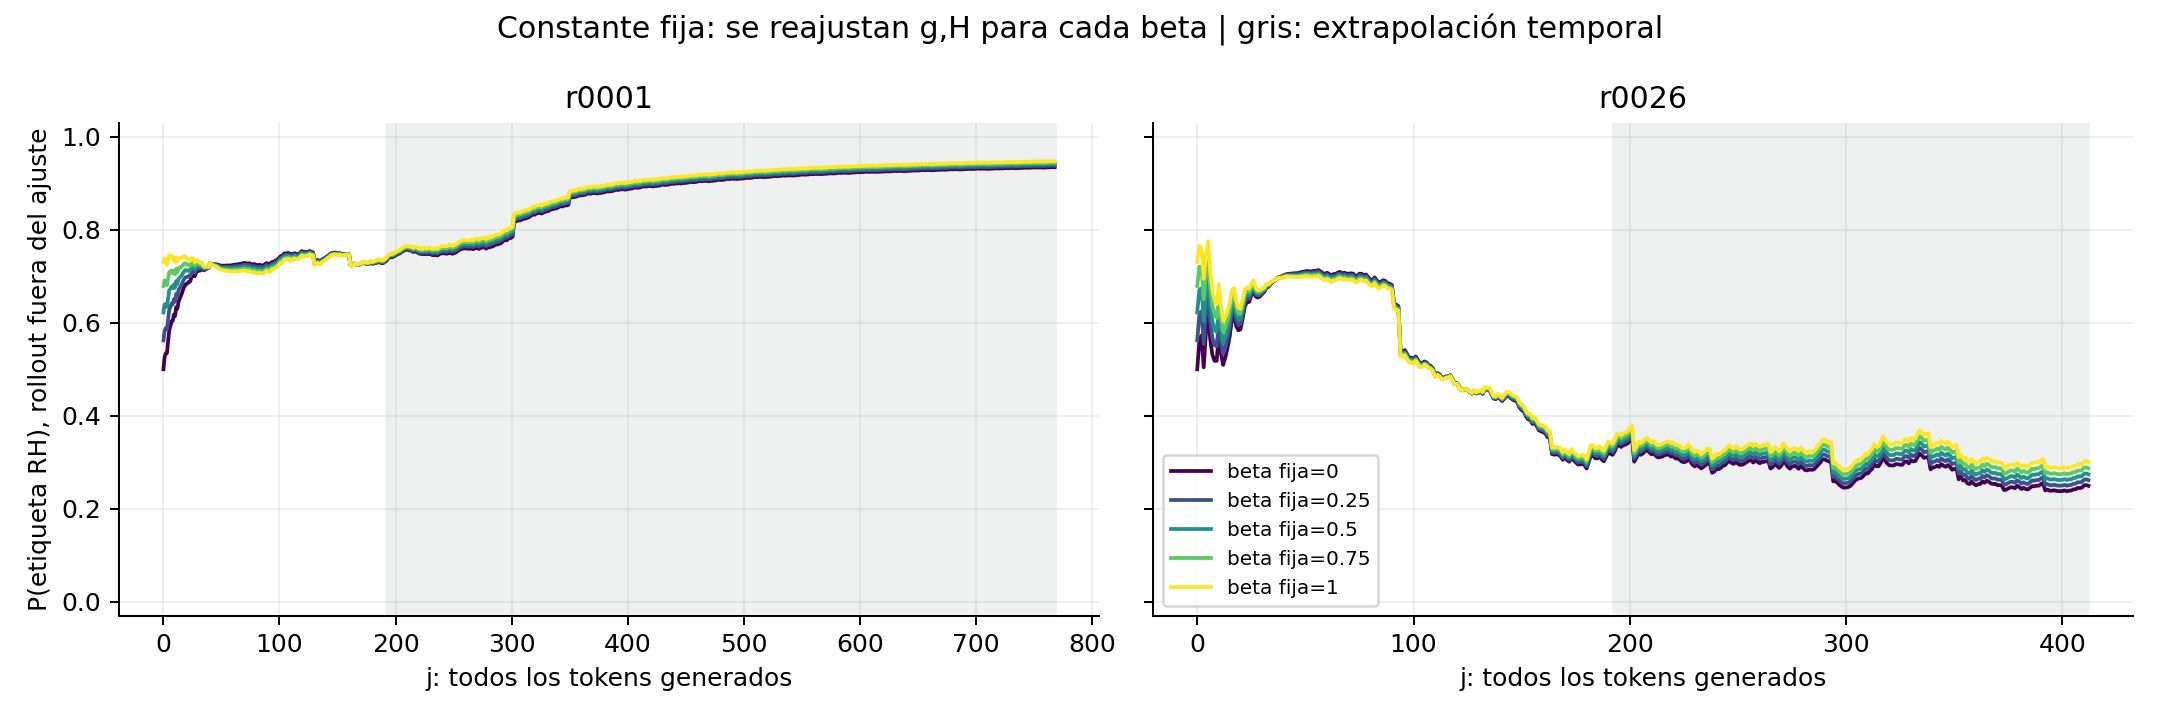

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(SALIDA/'05_fixed_intercept_case_trajectories.png')))

## Lectura de esta corrida

Las curvas de ambos casos contienen todos los j; el entrenamiento sigue usando
cinco prefijos. A partir de j=193 se muestra extrapolacion temporal, no evaluacion
en un horizonte usado durante el entrenamiento. Los dos casos son ejemplos
seleccionados y no sustituyen la evaluacion sobre los 72 rollouts.

Las cinco inicializaciones convergieron con una diferencia maxima de probabilidad
de 1.35e-5 (entre 60 y 511 iteraciones). Esto respalda insensibilidad a la
inicializacion en esta optimizacion, no ausencia de sesgo de muestreo. La constante
fija cambia el problema: su influencia por token se muestra en la quinta figura.

En j=192, AUROC/log-loss son: diagonal 0.690/0.553, completo 0.670/0.583 y
cubico 0.681/0.563. El cubico mejora frente al completo, pero no supera al
diagonal en esas dos metricas. Su exactitud balanceada a umbral 0.5 es 0.580,
frente a 0.532 diagonal: los criterios no ordenan exactamente igual los modelos.
La muestra y el esquema de seguimiento no justifican declarar necesario el
tensor cubico. No hay prueba de generalizacion entre prompts.
